# 01 우동호 외(2023) 마법공식 재현

## 0. 원문 정리 (원문을 먼저 읽고 옮김)
원문: 우동호·최흥식·김선웅(2023), 「한국주식시장에서의 마법공식 투자전략 성과분석」, 한국산학기술학회논문지 24(3), 508–519. 3.1·3.2절(p.512–513), 표 1~7(p.512–516).

| 항목 | 원문 | 쪽 | 우리 설정 (`공통/포트폴리오.py`의 `우동호2023`) |
|---|---|---|---|
| 대상 시장 | 유가증권시장 + 코스닥시장 | 512 | `시장=["KS","KQ"]` (CP10000300) |
| 제외 업종 | 은행·보험·증권·투자금융·신용금고·종합금융·기타금융 | 512 | `금융업`: 그날 거래소 업종명(CP10001090)에 은행·보험·증권·금융·금고. 업종이 빈 종목만 이름 규칙. WICS 대분류 '금융'은 확인용으로 기록에만 셈. 이어서 `투자기구`: 선박투자회사·부동산투자회사(CR리츠)·리츠(이름 규칙) |
| 결산월 | 12월 결산법인만 | 512 | `("결산월", {"월": 12})` (회계연도별 결산월 이력 CP10002200) |
| 거래정지 | 거래일 기준 시점에 거래중지면 제외 | 512 | `거래정지` (일간 S410002600) |
| 가격 | 액면분할 등이 반영된 수정주가 | 512 | `가격=수정주가` (S410000700, 배당 미포함) |
| 리밸런싱 | 매년 4월 첫 거래일, 1년 보유 후 전량 교체 | 512–513 | `기준일="첫거래일"`, `리밸런싱=12`, `전량교체=True` |
| 재무 자료 | 직전 연도(t−1) 결산자료 | 512 | 본문 `재무시점=("결산후개월", 3)`: 결산일 + 3개월(발표일 안 봄). 확인판 `("발표일", 150)`: 발표일이 기록된 보고서는 그날까지 발표된 것만, 기록이 없으면 결산일 + 150일 |
| ROC | EBIT / (순운전자본 + 순고정자산), 순운전자본 = 유동자산 − 유동부채, 순고정자산 = 총자산 − 무형자산 | 512 | `지표.ROC` (무형자산 M000901024) |
| EBIT | 법인세차감전이익 + 이자비용 | 512 | `지표.EBIT` = 세전계속사업이익 M000907001 + 이자비용 M000906020 |
| EY | EBIT / 기업가치, 기업가치 = 시가총액 + 부채총액 − 현금 | 512 | `지표.EY` (시가총액 = 4월 첫 거래일 값) |
| 순위 | ROC·EY 각각 내림차순 순위 → 합산 | 512 | `합산="순위합산"` |
| 종목 수·비중 | 총 순위 상위 30종목 동일비중 | 512 | `고르기=("상위N", 30)`, `비중=["동일"]` |
| IMF(개선 공식) | ROC 대신 GP/A | 513 | `지표=[("GPA","높게"),("EY","높게")]`, GP/A = 매출총이익(M000904007) / 자산총계 (원문 p.513 'GP/A는 매출총이익을 총자산으로 나누어 계산한다', Novy-Marx 2013) |
| 거래비용 | 수수료 0.015%, 거래세 0.25%, 매수·매도마다 슬리피지 0.5% | 512 | `거래비용=dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005)` |
| 무위험이자율 | 3년 만기 국고채 | 513 | `무위험="E11.02.003.008"` (DataGuide 국고3년) |
| 벤치마크 | KOSPI | 513 | `시장지수="I.001"` |
| EBIT 서술(2.3절) | 영업이익에서 비영업활동 손익을 빼고 영업외·특별손익 중 영업활동 손익은 더한 금액, 법인세차감전이익에 이자비용을 더함 | 511 | 3.2절 식과 같은 끝(세전계속사업이익 + 이자비용) |
| 표본 표(표 1) | 연도별 Number·Average return·Standard deviation(%) | 512 | Number만 10절에 옮김. 평균수익률·표준편차는 '원문 차이 진단' 절에서 대조 |
| 성과 지표 | 누적수익률, 표준편차, MDD, 샤프, 정보비율, 젠센 알파, FF3, Carhart 4요인 | 513 | `평가.성과` |
| 요인 | SMB = 시총 하위30% − 상위30%, HML = BM 상위30% − 하위30%, MOM = 과거 11개월 상위30% − 하위30% | 513 | DataGuide 2×3 SMB·HML, 2×3 Mom (만든 방법이 원문과 같은지 미확인) |
| 기간 | 2004-04 ~ 2022-03 (2003~2020 결산자료) | 512 | `기간=("2004-04","2022-03")`, `"끝": "마지막거래일"` (마지막 구간 = 2022-03 첫 거래일 → 2022-03-31, 원문대로. 2026-11-04 고침, 전에는 2022-04-01까지라 하루 더 있었음) |
| 규모별 | 전체 종목을 시가총액 5분위로 나눠 분위마다 따로 | 514–516 | `("시총분위", {"분위": q})` 추가 |
| 수업 형식(추가) | — | — | 5분위, EW·VW, LS = Q1 − Q5 (비용 0) |

원문 안에서 서로 맞지 않는 곳(우리가 고치지 않음, 0단계 대조 2026-11-04): p.512 본문은 2020년 평균수익률 96.69%, 표 1은 98.69 / p.517 결론의 '4분위 마법공식 (−) 알파'는 표 6(4분위)에는 음수가 없고 표 7(5분위) MF 4F −0.0003뿐.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 새로 통째로 받은 파일(읽기.DATA 기본 = data\통합_전체_202611, DataGuide 달력기준 일간)로 원문 기간을 돌린다.
기간 = ("2004-04", "2022-03")  # 원문 p.512 2004년 4월~2022년 3월. 마지막 구간은 2022-03 마지막 거래일에서 끊음(아래 "끝")
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611 / 기간: ('2004-04', '2022-04')


## 3. 설정: 본문과 확인판
- **본문**: 원문대로 '4월 첫 거래일, 직전 연도 결산자료'. 12월 결산이면 결산일 + 3개월(3월 말)이 지나면 쓴다(발표일은 보지 않음).
- **A070480(신비앤텍)**: 큰 수익률이 결과를 움직였는지 보려고 이 종목을 뺀 판을 두었었다(회원 결정 2026-11-02). 상위 30에 한 번도 들지 않아 본문과 똑같은 열이 두 번 잡혀서 뺐다(2026-11-04, README 한계 'A070480 빼기 중복'). 11절에서 보유 횟수를 직접 센다(0이 아니면 멈춤).
- **확인판**: 발표일(FP56000900)이 기록된 보고서는 그 다음 거래일부터 쓴다. 발표일 기록이 없는 보고서는 결산일 + 150일부터 쓴다. 그때까지 안 나온 회사는 그 직전 결산자료를 쓴다(150일은 근거 없음(02 노트북 3절 표는 늦은 발표 비율만 보여 줌: 99% 칸 104~125일, '150일 초과' 0.7%)). 이른 연도는 발표일 기록이 드물어(02 노트북 3절 '발표일 있음' 칸) 확인판이 사실상 '결산일 + 150일' 규칙이 된다. 6절에서 행마다 어느 쪽인지 센다.

In [3]:
IMF = {"이름": "우동호2023_IMF", "지표": [("GPA", "높게"), ("EY", "높게")]}
설정 = {"MF": {**포.우동호2023, "기간": 기간, "끝": "마지막거래일"}, "IMF": {**포.우동호2023, **IMF, "기간": 기간, "끝": "마지막거래일"}}
설정 |= {f"{k}_확인판": {**v, "이름": v["이름"] + "_확인판", "재무시점": ("발표일", 150)} for k, v in list(설정.items())}
pd.DataFrame(설정).astype(str)

,MF,IMF,MF_확인판,IMF_확인판,MF_A070480빼기,IMF_A070480빼기
시장,"['KS', 'KQ']","['KS', 'KQ']","['KS', 'KQ']","['KS', 'KQ']","['KS', 'KQ']","['KS', 'KQ']"
가격,S410000700,S410000700,S410000700,S410000700,S410000700,S410000700
기간,"('2004-04', '2022-04')","('2004-04', '2022-04')","('2004-04', '2022-04')","('2004-04', '2022-04')","('2004-04', '2022-04')","('2004-04', '2022-04')"
기준일,첫거래일,첫거래일,첫거래일,첫거래일,첫거래일,첫거래일
리밸런싱,12,12,12,12,12,12
재무시점,"('결산후개월', 3)","('결산후개월', 3)","('발표일', 150)","('발표일', 150)","('결산후개월', 3)","('결산후개월', 3)"
제외,"['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래..."
지표,"[('ROC', '높게'), ('EY', '높게')]","[('GPA', '높게'), ('EY', '높게')]","[('ROC', '높게'), ('EY', '높게')]","[('GPA', '높게'), ('EY', '높게')]","[('ROC', '높게'), ('EY', '높게')]","[('GPA', '높게'), ('EY', '높게')]"
합산,순위합산,순위합산,순위합산,순위합산,순위합산,순위합산
고르기,"('상위N', 30)","('상위N', 30)","('상위N', 30)","('상위N', 30)","('상위N', 30)","('상위N', 30)"


## 4. 본문: 상위 30종목, EW·VW
4월 첫 거래일마다 거르기 → 지표 계산 → 순위 합산 → 상위 30종목을 사서 1년 보유한다. EW(동일가중)가 원문, VW(시가총액가중)는 추가.
KOSPI는 같은 기준일 간격의 지수 수익률이다. KOSPI 행의 알파·t는 시장을 자기 자신에 회귀한 값이라 뜻이 없다(0에 가까운 수치 잡음).
'이상값 보유' 칸 = 그 포트폴리오가 보유한 달 가운데 종목 수익률이 한 달 +300%를 넘은 종목-월 수(11절 표 기준). 0보다 크면 그 줄은 **이상값 영향**이 있다.

In [4]:
결과 = {k: 포.실행({**v, "비중": ["동일", "시총"]}) for k, v in 설정.items()}
F = 평가.요인(포.기준일(설정["MF"]), 설정["MF"])
R = pd.DataFrame({f"{k}_{b}": o["수익률"][(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]})
R["KOSPI"] = F["시장"]
R = R.dropna(how="all")
표 = 평가.성과표(R, F)
표.insert(0, "이상값 보유", pd.Series({f"{k}_{b}": 포.이상값보유(o)[(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]}))
표

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
MF_동일,0.0000,216.0000,7.3090,0.1248,0.2613,0.4683,-0.5911,0.4040,0.0102,1.9868,1.8831,0.0059,1.6920,1.6217,0.0025,0.8361,0.8493,0.0026,0.8924,0.9121,1.0119,0.7445,0.0813,-0.0365,0.6987
MF_시총,0.0000,216.0000,9.3213,0.1385,0.3010,0.4786,-0.6112,0.3822,0.0120,2.0306,2.0260,0.0080,1.6737,1.6793,0.0060,1.2290,1.3383,0.0065,1.3219,1.4482,0.9331,0.3227,0.0829,-0.0978,0.3676
IMF_동일,0.0000,216.0000,12.9303,0.1576,0.2413,0.6026,-0.5465,0.5558,0.0121,2.5567,2.3277,0.0083,2.4837,2.3098,0.0049,1.8735,1.7470,0.0049,1.8720,1.7540,0.9066,0.8093,0.0571,-0.0083,0.7248
IMF_시총,0.0000,216.0000,14.3933,0.1640,0.2308,0.6446,-0.3405,0.5158,0.0124,2.7348,3.0700,0.0092,2.5658,2.6214,0.0073,2.0018,1.9439,0.0071,1.9217,1.8837,0.7408,0.3051,0.0867,0.0442,0.4017
MF_확인판_동일,0.0000,216.0000,6.9775,0.1223,0.2613,0.4598,-0.5879,0.3836,0.0100,1.9507,1.8647,0.0058,1.6267,1.5884,0.0022,0.7234,0.7416,0.0024,0.7929,0.8149,0.9947,0.7700,0.0917,-0.0439,0.6910
MF_확인판_시총,0.0000,216.0000,7.7551,0.1281,0.3110,0.4406,-0.6058,0.3266,0.0114,1.8692,1.8805,0.0076,1.4805,1.4902,0.0055,1.0306,1.1429,0.0060,1.1288,1.2606,0.8813,0.3389,0.0978,-0.1093,0.3097
IMF_확인판_동일,0.0000,216.0000,11.2813,0.1495,0.2462,0.5659,-0.5465,0.5069,0.0116,2.4009,2.2006,0.0077,2.2534,2.1249,0.0044,1.6917,1.5634,0.0046,1.7304,1.6072,0.9199,0.8485,0.0303,-0.0275,0.7322
IMF_확인판_시총,0.0000,216.0000,16.1707,0.1711,0.2382,0.6568,-0.3405,0.5513,0.0130,2.7865,2.8490,0.0097,2.6452,2.5161,0.0071,1.9888,1.8168,0.0069,1.9168,1.7820,0.7795,0.4729,0.0934,0.0375,0.4581
MF_A070480빼기_동일,0.0000,216.0000,7.3090,0.1248,0.2613,0.4683,-0.5911,0.4040,0.0102,1.9868,1.8831,0.0059,1.6920,1.6217,0.0025,0.8361,0.8493,0.0026,0.8924,0.9121,1.0119,0.7445,0.0813,-0.0365,0.6987
MF_A070480빼기_시총,0.0000,216.0000,9.3213,0.1385,0.3010,0.4786,-0.6112,0.3822,0.0120,2.0306,2.0260,0.0080,1.6737,1.6793,0.0060,1.2290,1.3383,0.0065,1.3219,1.4482,0.9331,0.3227,0.0829,-0.0978,0.3676


## 5. 누적수익률 그림

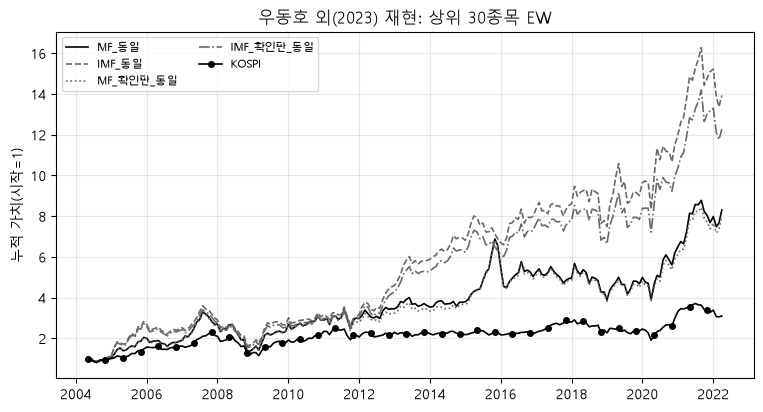

In [5]:
평가.누적그림(R[["MF_동일", "IMF_동일", "MF_확인판_동일", "IMF_확인판_동일", "KOSPI"]], "우동호 외(2023) 재현: 상위 30종목 EW");

## 6. 본문 vs 확인판: 종목 수와 결과
첫 표는 리밸런싱마다 순위를 매긴 종목 수(거르기 뒤 − 지표 빈칸). 둘째 표는 첫 리밸런싱일에 종목마다 쓴 결산자료의 회계연도(행 = 본문, 열 = 확인판). 셋째 표는 성과.

In [6]:
display(pd.DataFrame({k: (o["기록"]["거래정지"] - o["기록"]["빈칸으로 빠짐"]).set_axis(o["기록"].index.year) for k, o in 결과.items()}).rename_axis("순위 매긴 종목 수"))
t0 = 포.기준일(설정["MF"])[0]
a, b = 포.재무(t0, 설정["MF"]["재무시점"]), 포.재무(t0, 설정["MF_확인판"]["재무시점"])
display(pd.crosstab(a["회계연도"], b["회계연도"].reindex(a.index).fillna(0).astype(int), rownames=["본문 회계연도"], colnames=["확인판 회계연도(0=없음)"]))
display(pd.crosstab(b["회계연도"], b["발표일"].notna().map({True: "발표일 기록 있음", False: "기록 없음 → 결산일+150일"}), rownames=["확인판 회계연도"], colnames=["확인판이 쓴 행"]))
_, c0, _ = 포.거르기(t0, 설정["MF"])
print(f"{t0:%Y-%m-%d} 거르기 뒤 {len(c0)}종목 중 본문이 쓴 결산자료의 실제 발표일이 그날 이후인 종목(원문 규칙의 미래 정보): {int((a['발표일'].reindex(c0) >= t0).sum())}")
표.loc[["MF_동일", "MF_확인판_동일", "IMF_동일", "IMF_확인판_동일"], ["누적", "연환산", "표준편차(연)", "샤프", "MDD", "CAPM α(월)", "Carhart α(월)", "Carhart t(NW)"]]

,MF,IMF,MF_확인판,IMF_확인판,MF_A070480빼기,IMF_A070480빼기
순위 매긴 종목 수,,,,,,
2004,1028,1246,1037,1254,1028,1246
2005,1044,1250,1039,1247,1044,1250
2006,1096,1294,1096,1294,1096,1294
2007,1168,1358,1167,1357,1168,1358
2008,1200,1395,1200,1395,1200,1395
2009,1206,1406,1206,1407,1206,1406
2010,1230,1429,1231,1429,1230,1429
2011,1251,1441,1251,1441,1251,1441
2012,1473,1494,1472,1494,1473,1494


확인판 회계연도(0=없음),0,2002,2003
본문 회계연도,,,
2002,0,440,0
2003,48,2914,1490


확인판이 쓴 행,기록 없음 → 결산일+150일,발표일 기록 있음
확인판 회계연도,,
2002,3125,229
2003,187,1303


2004-04-01 거르기 뒤 1334종목 중 본문이 쓴 결산자료의 실제 발표일이 그날 이후인 종목(원문 규칙의 미래 정보): 10


,누적,연환산,표준편차(연),샤프,MDD,CAPM α(월),Carhart α(월),Carhart t(NW)
MF_동일,7.3090,0.1248,0.2613,0.4683,-0.5911,0.0059,0.0026,0.9121
MF_확인판_동일,6.9775,0.1223,0.2613,0.4598,-0.5879,0.0058,0.0024,0.8149
IMF_동일,12.9303,0.1576,0.2413,0.6026,-0.5465,0.0083,0.0049,1.7540
IMF_확인판_동일,11.2813,0.1495,0.2462,0.5659,-0.5465,0.0077,0.0046,1.6072


## 7. 수업 형식: 5분위·LS(Q1 − Q5), EW·VW
같은 순위로 종목을 5묶음으로 나눈다. Q1이 총 순위가 가장 좋은 묶음이다. '이상값 영향' 칸은 그 묶음이 한 달 +300% 초과 종목-월(11절)을 보유했는지 표시한다. LS는 Q1을 사고 Q5를 판 수익률이다. 분위·LS는 수업 형식대로 **거래비용 0**으로 돌린다(비용을 뺀 Q5를 빼면 숏 쪽 비용 부호가 거꾸로 되기 때문). 본문 설정만.

In [7]:
비용0 = dict(수수료=0, 거래세=0, 슬리피지=0)
분위 = {k: 포.실행({**설정[k], "고르기": ("분위", 5), "비중": ["동일", "시총"], "거래비용": 비용0}) for k in ["MF", "IMF"]}
Q = {}
for k, o in 분위.items():
    for b in ["동일", "시총"]:
        r = o["수익률"][b]
        Q.update({f"{k}_{b}_{g}": r[g] for g in r})
        Q[f"{k}_{b}_LS"] = r["Q1"] - r["Q5"]
Q = pd.DataFrame(Q)
분위표 = 평가.성과표(Q, F, [c for c in Q if c.endswith("LS")])
영향 = {f"{k}_{b}_{g}": n for k, o in 분위.items() for (b, g), n in 포.이상값보유(o).items()}
영향 |= {f"{k}_{b}_LS": 영향[f"{k}_{b}_Q1"] + 영향[f"{k}_{b}_Q5"] for k in 분위 for b in ["동일", "시총"]}
분위표.insert(0, "이상값 보유", pd.Series(영향))
분위표.insert(1, "이상값 영향", 분위표["이상값 보유"].gt(0).map({True: "이상값 영향", False: ""}))
분위표

,이상값 보유,이상값 영향,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
MF_동일_Q1,4,이상값 영향,216.0000,9.5093,0.1396,0.2252,0.5619,-0.5510,0.6360,0.0106,2.3839,2.2030,0.0063,2.6823,2.6556,0.0029,2.3303,2.4545,0.0027,2.1349,2.1497,1.0031,0.7369,0.0802,0.0449,0.9278
MF_동일_Q2,2,이상값 영향,216.0000,11.6468,0.1514,0.2345,0.5929,-0.5324,0.7026,0.0116,2.5153,2.3504,0.0071,2.9046,2.9149,0.0039,3.1413,3.6216,0.0034,2.7838,2.8935,1.0412,0.7918,0.0531,0.0965,0.9375
MF_동일_Q3,4,이상값 영향,216.0000,12.6757,0.1564,0.2463,0.5941,-0.5477,0.6759,0.0122,2.5207,2.3224,0.0077,2.7717,2.8671,0.0042,3.2625,3.6216,0.0039,3.0256,3.3534,1.0621,0.9048,0.0321,0.0581,0.9362
MF_동일_Q4,8,이상값 영향,216.0000,8.0748,0.1304,0.2596,0.4870,-0.6327,0.4665,0.0106,2.0664,1.8489,0.0060,1.8848,1.8255,0.0032,2.3505,2.5198,0.0035,2.5761,2.8990,1.0734,1.0364,-0.0855,-0.0594,0.9369
MF_동일_Q5,22,이상값 영향,216.0000,0.9433,0.0376,0.2707,0.1610,-0.7640,-0.0387,0.0036,0.6830,0.5421,-0.0004,-0.0996,-0.0819,-0.0024,-1.1415,-0.9801,-0.0018,-0.8515,-0.6882,0.9510,1.1997,-0.2227,-0.1215,0.8547
MF_동일_LS,26,이상값 영향,216.0000,2.5707,0.0733,0.1548,0.5360,-0.5151,0.0063,0.0069,2.2741,1.7899,0.0067,2.1829,1.7120,0.0054,1.9688,1.6682,0.0045,1.6626,1.3225,0.0521,-0.4627,0.3030,0.1664,0.2868
MF_시총_Q1,4,이상값 영향,216.0000,3.5686,0.0881,0.1834,0.3890,-0.4214,0.2452,0.0060,1.6503,1.6966,0.0022,1.4598,1.5814,0.0023,1.4680,1.5318,0.0025,1.5307,1.7081,0.8682,-0.0332,0.0000,-0.0233,0.8217
MF_시총_Q2,2,이상값 영향,216.0000,1.8532,0.0600,0.2121,0.2409,-0.5695,-0.0051,0.0043,1.0223,0.9852,-0.0002,-0.1090,-0.1289,0.0009,0.6033,0.7399,0.0003,0.2009,0.2481,1.0359,0.0503,-0.1274,0.1207,0.8804
MF_시총_Q3,4,이상값 영향,216.0000,3.6613,0.0893,0.2384,0.3536,-0.5075,0.3264,0.0070,1.5000,1.4607,0.0021,1.1222,1.3297,0.0021,1.1033,1.1543,0.0014,0.7253,0.7964,1.1392,0.1552,-0.0516,0.1455,0.8492
MF_시총_Q4,8,이상값 영향,216.0000,2.1218,0.0653,0.2486,0.2595,-0.6194,0.1051,0.0054,1.1008,1.0595,0.0005,0.2144,0.2188,0.0000,0.0106,0.0116,-0.0002,-0.0734,-0.0824,1.1375,0.3764,-0.0839,0.0363,0.8090


## 8. 시가총액 5분위별 (원문 표 3~7)
4월 첫 거래일 시가총액으로 거른 뒤 종목을 5분위로 나누고(1분위 = 가장 작음), 분위마다 따로 상위 30종목을 고른다. 본문 설정만.

In [8]:
규모결과 = {f"{k}_시총{q}분위": 포.실행({**설정[k], "제외": 설정[k]["제외"] + [("시총분위", {"분위": q})]}) for q in range(1, 6) for k in ["MF", "IMF"]}
규모 = pd.DataFrame({n: o["수익률"][("동일", "상위30")] for n, o in 규모결과.items()})
규모표 = 평가.성과표(규모, F)
규모표.insert(0, "이상값 보유", pd.Series({n: 포.이상값보유(o)[("동일", "상위30")] for n, o in 규모결과.items()}))
규모표

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
MF_시총1분위,2,216.0000,212.1018,0.3470,0.2885,1.0802,-0.5573,1.1615,0.0260,4.5828,4.3394,0.0219,4.9541,4.9045,0.0175,4.9778,5.6197,0.0177,4.9847,5.6267,0.9535,1.0523,0.0739,-0.0360,0.6461
IMF_시총1분위,2,216.0000,354.8223,0.3859,0.3030,1.1357,-0.5460,1.2003,0.0287,4.8184,4.4533,0.0247,5.1233,4.7904,0.0207,5.5591,6.2023,0.0205,5.4335,6.0706,0.9481,1.1743,-0.0169,0.0564,0.6393
MF_시총2분위,0,216.0000,20.2121,0.1849,0.2801,0.6378,-0.6225,0.6580,0.0149,2.7059,2.3402,0.0104,2.7144,2.7627,0.0044,1.9032,1.9076,0.0051,2.1925,2.1519,1.0589,1.1357,0.1967,-0.1265,0.8399
IMF_시총2분위,0,216.0000,24.5319,0.1972,0.2840,0.6697,-0.6301,0.6951,0.0159,2.8415,2.5261,0.0113,2.8763,2.8075,0.0056,2.2736,2.2119,0.0055,2.1942,2.2049,1.0580,1.1596,0.1705,0.0282,0.8198
MF_시총3분위,1,216.0000,4.7286,0.1018,0.2645,0.3850,-0.5834,0.2942,0.0085,1.6335,1.5187,0.0040,1.1755,1.1564,-0.0001,-0.0525,-0.0579,-0.0002,-0.0886,-0.0948,1.0558,0.8988,0.0971,0.0172,0.7995
IMF_시총3분위,1,216.0000,4.8274,0.1029,0.2605,0.3900,-0.5877,0.2946,0.0085,1.6545,1.5501,0.0040,1.2054,1.1950,0.0003,0.1194,0.1389,-0.0000,-0.0114,-0.0128,1.0332,0.8622,0.0763,0.0633,0.7796
MF_시총4분위,0,216.0000,1.4013,0.0499,0.2368,0.1979,-0.5156,-0.0306,0.0039,0.8397,0.8390,-0.0002,-0.0566,-0.0610,-0.0034,-1.4329,-1.4946,-0.0038,-1.6151,-1.7225,0.9522,0.7251,0.0705,0.0857,0.7665
IMF_시총4분위,0,216.0000,3.9618,0.0931,0.2266,0.3736,-0.5189,0.2234,0.0071,1.5850,1.4817,0.0032,1.1000,1.1270,0.0004,0.1654,0.1808,-0.0004,-0.1911,-0.2047,0.9036,0.7226,0.0343,0.1529,0.7767
MF_시총5분위,0,216.0000,1.5809,0.0541,0.2012,0.2151,-0.5085,-0.0761,0.0036,0.9124,0.8969,-0.0002,-0.1047,-0.1022,-0.0015,-0.7233,-0.6982,-0.0016,-0.7394,-0.7310,0.8913,0.2372,0.0474,0.0093,0.7427
IMF_시총5분위,0,216.0000,2.6300,0.0743,0.1824,0.3215,-0.4532,0.0616,0.0049,1.3641,1.3709,0.0016,0.7477,0.7420,0.0009,0.4424,0.4486,0.0007,0.3289,0.3271,0.7726,0.2820,-0.0309,0.0440,0.6978


## 9. 원문 vs 우리
원문 숫자는 표 2~7(p.514–516)을 옮겨 적은 것이고, 우리 숫자(본문 설정)는 위 표에서 코드가 가져온다. 누적·MDD·표준편차는 소수(980.35% → 9.8035).

In [9]:
열 = {"Return": "누적", "MDD": "MDD", "SD": "표준편차(연)", "Sharpe": "샤프", "IR": "정보비율",
     "Jensen α": "CAPM α(월)", "Jensen t": "CAPM t(OLS)", "3F α": "FF3 α(월)", "3F t": "FF3 t(OLS)", "4F α": "Carhart α(월)", "4F t": "Carhart t(OLS)"}
원문표 = pd.DataFrame({  # 우동호 외(2023) 표 2~7
    ("전체", "MF"): [9.8035, -0.5034, 0.9479, 2.42, 1.48, 0.0068, 2.32, -0.0050, -1.28, -0.0053, -1.34],
    ("전체", "IMF"): [10.2791, -0.4962, 0.8857, 2.58, 1.57, 0.0071, 2.47, -0.0028, -0.73, -0.0034, -0.87],
    ("전체", "KOSPI"): [2.1239, -0.5454, 0.8349, 1.34, 0.00] + [None] * 6,
    ("시총1분위", "MF"): [44.2427, -0.5760, 1.1082, 3.52, 2.72, 0.0137, 3.88, 0.0139, 3.51, 0.0141, 3.55],
    ("시총1분위", "IMF"): [101.3052, -0.6203, 1.1828, 4.06, 3.31, 0.0179, 4.39, 0.0167, 3.62, 0.0168, 3.64],
    ("시총2분위", "MF"): [17.6391, -0.5155, 1.0596, 2.78, 1.94, 0.0095, 2.76, 0.0097, 2.70, 0.0096, 2.69],
    ("시총2분위", "IMF"): [28.4832, -0.5343, 1.1032, 3.13, 2.32, 0.0120, 3.13, 0.0127, 3.25, 0.0126, 3.24],
    ("시총3분위", "MF"): [6.3007, -0.4963, 0.9663, 1.99, 1.07, 0.0049, 1.68, 0.0044, 1.46, 0.0044, 1.45],
    ("시총3분위", "IMF"): [9.8866, -0.4799, 0.9275, 2.47, 1.51, 0.0068, 2.38, 0.0066, 2.22, 0.0066, 2.21],
    ("시총4분위", "MF"): [2.0623, -0.5528, 0.9325, 1.10, 0.14, 0.0009, 0.33, 0.0005, 0.18, 0.0004, 0.13],
    ("시총4분위", "IMF"): [2.7631, -0.5583, 0.9242, 1.32, 0.35, 0.0020, 0.68, 0.0031, 0.99, 0.0028, 0.90],
    ("시총5분위", "MF"): [3.3954, -0.4398, 0.7890, 1.59, 0.47, 0.0022, 1.13, 0.0004, 0.20, -0.0003, -0.15],
    ("시총5분위", "IMF"): [3.7548, -0.3496, 0.6953, 1.82, 0.54, 0.0028, 1.47, 0.0018, 0.86, 0.0011, 0.57],
}, index=list(열)).T
우리 = {("전체", "MF"): 표.loc["MF_동일"], ("전체", "IMF"): 표.loc["IMF_동일"], ("전체", "KOSPI"): 표.loc["KOSPI"]}
우리 |= {(f"시총{q}분위", k): 규모표.loc[f"{k}_시총{q}분위"] for q in range(1, 6) for k in ["MF", "IMF"]}
우리표 = pd.DataFrame({k: v[list(열.values())].to_numpy() for k, v in 우리.items()}, index=list(열)).T
print("우리 = 본문 설정 / 기간", 기간, "/ 우리 개월 수", int(표.loc["MF_동일", "개월"]))
대조 = pd.concat({"원문": 원문표, "우리": 우리표}, axis=1).swaplevel(axis=1)[list(열)]
대조.to_csv(평가.결과폴더 / "01_원문대조.csv", encoding="utf-8-sig")  # 결과요약 노트북이 읽음
대조

우리 = 본문 설정 / 기간 ('2004-04', '2022-04') / 우리 개월 수 216


Return              MDD             SD        Sharpe            IR         Jensen α         Jensen t            3F α            3F t            4F α            4F t        
                  원문       우리      원문      우리     원문     우리     원문     우리     원문      우리       원문      우리       원문      우리      원문      우리      원문      우리      원문      우리      원문      우리
전체    MF      9.8035   7.3090 -0.5034 -0.5911 0.9479 0.2613 2.4200 0.4683 1.4800  0.4040   0.0068  0.0059   2.3200  1.6920 -0.0050  0.0025 -1.2800  0.8361 -0.0053  0.0026 -1.3400  0.8924
      IMF    10.2791  12.9303 -0.4962 -0.5465 0.8857 0.2413 2.5800 0.6026 1.5700  0.5558   0.0071  0.0083   2.4700  2.4837 -0.0028  0.0049 -0.7300  1.8735 -0.0034  0.0049 -0.8700  1.8720
      KOSPI   2.1239   2.1038 -0.5454 -0.5062 0.8349 0.1917 1.3400 0.2687 0.0000     NaN      NaN  0.0000      NaN     NaN     NaN  0.0000     NaN     NaN     NaN  0.0000     NaN     NaN
시총1분위 MF     44.2427 212.1018 -0.5760 -0.5573 1.1082 0.2885 3.5200 1.0802 2.7200  1.1615   0.0137  0.0219   3.8800  4.9541  0.0139  0.0175  3.5100  4.9778  0.0141  0.0177  3.5500  4.9847
      IMF   101.3052 354.8223 -0.6203 -0.5460 1.1828 0.3030 4.0600 1.1357 3.3100  1.2003   0.0179  0.0247   4.3900  5.1233  0.0167  0.0207  3.6200  5.5591  0.0168  0.0205  3.6400  5.4335
시총2분위 MF     17.6391  20.2121 -0.5155 -0.6225 1.0596 0.2801 2.7800 0.6378 1.9400  0.6580   0.0095  0.0104   2.7600  2.7144  0.0097  0.0044  2.7000  1.9032  0.0096  0.0051  2.6900  2.1925
      IMF    28.4832  24.5319 -0.5343 -0.6301 1.1032 0.2840 3.1300 0.6697 2.3200  0.6951   0.0120  0.0113   3.1300  2.8763  0.0127  0.0056  3.2500  2.2736  0.0126  0.0055  3.2400  2.1942
시총3분위 MF      6.3007   4.7286 -0.4963 -0.5834 0.9663 0.2645 1.9900 0.3850 1.0700  0.2942   0.0049  0.0040   1.6800  1.1755  0.0044 -0.0001  1.4600 -0.0525  0.0044 -0.0002  1.4500 -0.0886
      IMF     9.8866   4.8274 -0.4799 -0.5877 0.9275 0.2605 2.4700 0.3900 1.5100  0.2946   0.0068  0.0040   2.3800  1.2054  0.0066  0.0003  2.2200  0.1194  0.0066 -0.0000  2.2100 -0.0114
시총4분위 MF      2.0623   1.4013 -0.5528 -0.5156 0.9325 0.2368 1.1000 0.1979 0.1400 -0.0306   0.0009 -0.0002   0.3300 -0.0566  0.0005 -0.0034  0.1800 -1.4329  0.0004 -0.0038  0.1300 -1.6151
      IMF     2.7631   3.9618 -0.5583 -0.5189 0.9242 0.2266 1.3200 0.3736 0.3500  0.2234   0.0020  0.0032   0.6800  1.1000  0.0031  0.0004  0.9900  0.1654  0.0028 -0.0004  0.9000 -0.1911
시총5분위 MF      3.3954   1.5809 -0.4398 -0.5085 0.7890 0.2012 1.5900 0.2151 0.4700 -0.0761   0.0022 -0.0002   1.1300 -0.1047  0.0004 -0.0015  0.2000 -0.7233 -0.0003 -0.0016 -0.1500 -0.7394
      IMF     3.7548   2.6300 -0.3496 -0.4532 0.6953 0.1824 1.8200 0.3215 0.5400  0.0616   0.0028  0.0016   1.4700  0.7477  0.0018  0.0009  0.8600  0.4424  0.0011  0.0007  0.5700  0.3289

## 10. 표본 수: 원문 표 1 vs 우리, 첫 리밸런싱일 거르기 단계별
원문 3.1절의 표본 조건: 유가증권 + 코스닥, 은행·보험·증권·투자금융·신용금고·종합금융·기타금융 제외, 12월 결산, 필요한 자료 입수 가능, 기준일 거래정지 제외.
금융업 다음 단계 `투자기구`는 선박투자회사·부동산투자회사(CR리츠)·리츠를 이름으로 뺀다(일반기업과 재무제표 형태가 달라 금융업을 빼는 이유와 같음). 마지막 표는 리밸런싱 연도별로 투자기구로 빠진 수와, **이자비용 빈칸 때문에 빠진 수**(이자비용만 빈칸이고 나머지 재료는 다 있는 종목)를 센다. 빈칸은 채우지 않는다.
마지막 단계 '재료 전부 있음'은 원문의 '입수 가능'에 해당한다: ROC·EY에 드는 세전이익·이자비용·유동자산·유동부채·자산총계·무형자산·현금·부채총계·시가총액이 모두 있는 종목.
(우리 설정에는 원문에 없는 `보통주`(코드 끝자리 0) 단계와, 항상 `시장` 다음에 오는 `쓰지말것` 단계(README_데이터의 '쓰지 말 것' 구간이 보유 기간에 걸리는 종목)도 있어 함께 보인다.) 850에 맞추려고 조건을 새로 만들지 않는다.

In [10]:
표1 = pd.Series([850, 900, 972, 1033, 1098, 1129, 1196, 1282, 1351, 1382, 1434, 1484, 1568, 1638, 1744, 1815, 1880, 1955],
               index=range(2004, 2022), name="원문 표1")
기록 = 결과["MF"]["기록"]
display(pd.concat([표1, (기록["거래정지"] - 기록["빈칸으로 빠짐"]).set_axis(기록.index.year).rename("우리: 순위 매김")], axis=1).dropna())
s, c, n = 포.거르기(t0, 설정["MF"])
재료 = {"세전이익": 지표.세전이익, "이자비용": 지표.이자비용, "유동자산": 지표.유동자산, "유동부채": 지표.유동부채, "자산총계": 지표.자산,
       "무형자산": 지표.무형자산, "현금": 지표.현금, "부채총계": 지표.부채}
x = s["fin"].loc[c, list(재료.values())].set_axis(list(재료), axis=1).assign(시가총액=s["mcap"][c])
n["재료 전부 있음"] = int(x.notna().all(axis=1).sum())
display(pd.Series(n, name=f"{t0:%Y-%m-%d} 남은 종목 수").rename({"가격있음": "전체(그날 가격 있음)"}).to_frame())
display(x.isna().sum().rename("거래정지 단계 뒤 재료별 빈칸 수").to_frame())
이자 = 읽기.연간재무()[지표.이자비용]
print(f"연간재무 전체 이자비용: 값 있는 칸 {int(이자.notna().sum())}, 그중 0인 칸 {int((이자 == 0).sum())}")
print(f"원문 850 vs 우리 {n['재료 전부 있음']}")
연도별 = {}
for t in 결과["MF"]["기록"].index:  # 리밸런싱일만
    st, ct, nt = 포.거르기(t, 설정["MF"])
    xt = st["fin"].reindex(ct)[list(재료.values())].set_axis(list(재료), axis=1).assign(시가총액=st["mcap"].reindex(ct))
    빈 = xt["이자비용"].isna()
    나머지 = xt.drop(columns="이자비용").notna().all(axis=1)
    연도별[t.year] = {"투자기구로 빠짐": nt["금융업"] - nt["투자기구"], "거래정지 단계 뒤": len(ct), "이자비용 빈칸": int(빈.sum()),
                   "이자비용만 빈칸(나머지 재료 다 있음)": int((빈 & 나머지).sum()), "재료 전부 있음": int((~빈 & 나머지).sum())}
pd.DataFrame(연도별).T.rename_axis("리밸런싱 연도")

,원문 표1,우리: 순위 매김
2004,850,1028
2005,900,1044
2006,972,1096
2007,1033,1168
2008,1098,1200
2009,1129,1206
2010,1196,1230
2011,1282,1251
2012,1351,1473
2013,1382,1475


,2004-04-01 남은 종목 수
전체(그날 가격 있음),1754
시장,1754
쓰지말것,1753
보통주,1573
금융업,1490
투자기구,1484
결산월,1372
거래정지,1334
재료 전부 있음,1028


,거래정지 단계 뒤 재료별 빈칸 수
세전이익,3
이자비용,88
유동자산,3
유동부채,3
자산총계,3
무형자산,226
현금,3
부채총계,3
시가총액,0


연간재무 전체 이자비용: 값 있는 칸 72319, 그중 0인 칸 0
원문 850 vs 우리 1028


,투자기구로 빠짐,거래정지 단계 뒤,이자비용 빈칸,이자비용만 빈칸(나머지 재료 다 있음),재료 전부 있음
리밸런싱 연도,,,,,
2004,6,1334,88,80,1028
2005,22,1348,97,85,1044
2006,36,1403,109,93,1096
2007,49,1477,119,102,1168
2008,49,1525,129,108,1200
2009,46,1506,100,81,1206
2010,46,1535,105,84,1230
2011,42,1570,129,98,1251
2012,42,1581,87,81,1473


### 남은 차이의 원인 후보
- **표 1 'Number'의 정의**: 원문은 '표본 종목 수', '분석대상 기업의 종목 수는 850개'(p.512)라고만 하고, 어떤 기준으로 셌는지(재료가 모두 있는 수인지, 상장 기간 조건이 있는지)는 적지 않았다.
- **원문 데이터(TS2000)의 종목 범위**: 코스닥 소형주·상장 직후 종목의 재무 입수 범위가 DataGuide와 다를 수 있다.
- **'필요한 자료 입수 가능'의 범위**: t−1년 자료만인지, 더 이전 연도까지 요구했는지 알 수 없다.
- **금융업 범위**: 원문 7개 업종 이름이 거래소 업종(세부)과 1:1로 맞지 않는다. 거래소 업종이 빈 종목은 이름 규칙에만 걸린다(아래 확인 표의 `확인:업종빈칸` = 남은 종목 중 업종 빈칸 수, `확인:WICS금융` = 남은 종목 중 WICS가 금융으로 보는 수).
- **이자비용 빈칸**: 위 출력처럼 이자비용에 0인 칸이 없다면, 이자비용이 없는 회사가 0 대신 빈칸으로 들어 있을 수 있다. 빈칸은 빈칸 규칙이라 채우지 않고 '재료 전부 있음'에서 뺀다(빚 없는 회사가 빠지는 쪽으로 치우칠 수 있음).
- **원문에 적히지 않은 조건**: 우선주·관리종목·자본잠식 등이 TS2000 표본에서 빠져 있을 수 있다(확인 불가).
- **상장폐지 종목 포함 여부**: 원문에 서술이 없다.

## 11. 이상값: 한 달 수익률 +300% 초과 종목-월 (원본 값 공개)
원본 수정주가(상장 여부와 상관없이 값 있는 날 전부)로 기준일 간 종목 수익률을 계산해 +300%를 넘는 종목-월을 모두 보인다(이전 보고의 '3배 초과 98건'과 같은 계산). 값은 고치지 않는다.
- **그날 시장구분 / 상장 구간 수익률**: 실제 계산에 쓰는 값(시장구분이 코스피·코스닥인 날의 가격만). 빈칸이면 그 달은 장외·상장 전 가격이라 계산에서 빠진다.
- **쓰지 말 것**: 그 달이 README_데이터의 '쓰지 말 것' 구간에 걸리면 근거(D-05 등). 이런 종목은 걸리는 기간에 편입 대상에서 빠진다.
- **MF·IMF 보유**: 4절 상위 30 포트폴리오(본문, EW)가 그 종목-월을 실제로 보유했는지.
- A008080·A070480은 재조회(R28, 1988-01-01~2026-09-30)와 통합 파일의 차이가 0인 DataGuide 원래 값이다(회원 확인 2026-11-02).
- 끝에 코드 재사용 16종목(F5)의 경계 수익률이 끊기는지 센다.

In [11]:
g = 포.기준일(설정["MF"])
원시R = 포.기간수익률(읽기.일간(설정["MF"]["가격"]), g)
큰 = 포.큰수익률(원시R).to_frame("원본 가격 수익률")
상장R, 앞, 시장 = 결과["MF"]["종목수익률"], dict(zip(g[1:], g[:-1])), 읽기.일간(읽기.시장구분)
b = 읽기.쓰지말것(설정["MF"]["가격"])
큰["이름"] = 읽기.종목정보()["코드명"].reindex(큰.index.get_level_values(1)).to_numpy()
큰["그날 시장구분"] = [시장.at[d, c] if c in 시장 else None for d, c in 큰.index]
큰["상장 구간 수익률"] = [상장R.at[d, c] for d, c in 큰.index]
큰["쓰지 말 것"] = [", ".join(b.loc[(b["코드"] == c) & (b["시작"] <= d) & (b["끝"] >= 앞[d]), "근거"]) for d, c in 큰.index]
for k in ["MF", "IMF"]:
    W = 결과[k]["보유"][("동일", "상위30")]
    d0 = pd.DatetimeIndex(sorted(W))
    큰[f"{k} 보유"] = [bool((d0 < d).any()) and c in W[d0[d0 < d][-1]].index for d, c in 큰.index]
print(f"원본 가격 +300% 초과 {len(큰)}건 / 상장 구간 수익률도 +300% 초과 {int((큰['상장 구간 수익률'] > 3).sum())}건 / "
      f"'쓰지 말 것'에 걸림 {int(큰['쓰지 말 것'].ne('').sum())}건 / MF 보유 {int(큰['MF 보유'].sum())}건 / IMF 보유 {int(큰['IMF 보유'].sum())}건")
display(큰)
gg = 포.기준일({**설정["MF"], "기간": ("1990-01", "2026-09"), "끝": None})
RR = 포.기간수익률(읽기.상장가격(설정["MF"]["가격"]), gg)
u = pd.read_csv(읽기.새목록 / "코드재사용.csv", encoding="utf-8-sig", parse_dates=["새회사_첫날짜"])  # 새 데이터로 다시 만든 목록(예전 16종목 포함, B2 2026-11-04)
u = u[u["새회사_첫날짜"] < gg[-1]]
끊김 = [bool(pd.isna(RR.at[gg[gg > x][0], c])) if c in RR else True for c, x in zip(u["코드"], u["새회사_첫날짜"])]
print(f"코드 재사용 {len(u)}줄({u['코드'].nunique()}종목) 중 새 회사 첫 기준일 수익률이 빈칸(경계에서 끊김): {sum(끊김)}")
A070480 = {f"{k}_{b}": sum("A070480" in w.index for w in o["보유"][(b, "상위30")].values()) for k, o in 결과.items() for b in ["동일", "시총"]}
print("A070480(신비앤텍)을 보유한 리밸런싱 횟수:", A070480)
assert not any(A070480.values()), "A070480을 보유함 → 이 종목을 뺀 확인판을 다시 넣을 것(3절)"

원본 가격 +300% 초과 128건 / 상장 구간 수익률도 +300% 초과 94건 / '쓰지 말 것'에 걸림 1건 / MF 보유 0건 / IMF 보유 0건


원본 가격 수익률               이름 그날 시장구분  상장 구간 수익률 쓰지 말 것  MF 보유  IMF 보유
2004-05-03 A001745     3.7763          SK네트웍스우      KS     3.7763         False   False
2004-06-01 A001580     4.4423             신광기업      KS     4.4423         False   False
2004-07-01 A053595    19.4034        한국테크놀로지1우      KQ    19.4034         False   False
2005-01-03 A031390     6.7666             녹십자셀      KQ     6.7666         False   False
2005-02-01 A008040     7.2733            사조동아원      KS     7.2733         False   False
           A065770     3.3403               CS      KQ     3.3403         False   False
2005-04-01 A024870     4.2704       (주)유성티에스아이      KS     4.2704         False   False
2005-06-01 A032980     4.1098              바이온      KQ     4.1098         False   False
           A052880     3.7056           MOASNS      KQ     3.7056         False   False
2005-07-01 A010780     6.8648           아이에스동서      KS     6.8648         False   False
2005-08-01 A000420     3.8959         (주)로케트전기      KS     3.8959         False   False
           A000425     6.2066           로케트전기우      KS     6.2066         False   False
           A036760     5.7925           KNS홀딩스      KQ     5.7925         False   False
2005-11-01 A065910     3.4618      (주)피더블유제네틱스      KQ     3.4618         False   False
2005-12-01 A057330     7.4748            플래닛82      KQ     7.4748         False   False
           A080010     3.0239           이상네트웍스      KQ     3.0239         False   False
2006-01-02 A053890     3.5193         (주)미디어코프      KQ     3.5193         False   False
2006-02-01 A036660     3.3060           플러스프로핏      KQ     3.3060         False   False
2006-04-03 A058820     5.3292            CMG제약      KQ     5.3292         False   False
2006-10-02 A052210     8.4003        엠씨티티코어(주)      KQ     8.4003         False   False
2006-12-01 A009070     3.2030             KCTC      KS     3.2030         False   False
2007-02-01 A046430     3.7165          (주)알에스넷      KQ     3.7165         False   False
           A047710     3.1067             액티투오      KQ     3.1067         False   False
2007-03-02 A084810     4.3519          (주)아이알디      KQ     4.3519         False   False
2007-04-02 A033850     3.0454         (주)지노시스템      KQ     3.0454         False   False
2007-05-02 A008320     4.5535           한국기술산업      KS     4.5535         False   False
2007-06-01 A012090     3.2829          성원건설(주)      KS     3.2829         False   False
           A012095     3.0357            성원건설우      KS     3.0357         False   False
2007-09-03 A004965     5.0659            한신공영우      KS     5.0659         False   False
           A008405     5.1092           C&중공업우      KS     5.1092         False   False
           A023790     6.2104           동일스틸럭스      KQ     6.2104         False   False
           A050110     3.4382              캠시스      KQ     3.4382         False   False
2007-10-01 A000685     8.2265          LS네트웍스우      KS     8.2265         False   False
2007-11-01 A000685     3.1899          LS네트웍스우      KS     3.1899         False   False
2007-12-03 A001955     3.0214            남한제지우      KS     3.0214         False   False
2008-02-01 A006920     4.4794              모헨즈      KQ     4.4794         False   False
2008-05-02 A012805     3.4222             대창1우      KS     3.4222         False   False
2008-06-02 A002365     4.2816         SH에너지화학우      KS     4.2816         False   False
2009-06-01 A054180     4.2500             메디콕스      KQ     4.2500         False   False
2009-08-03 A005690     4.1543              파미셀      KS     4.1543         False   False
2010-04-01 A000590     3.9719            CS홀딩스      KS     3.9719         False   False
           A009620     7.3651             삼보산업      KQ     7.3651         False   False
           A120030     7.7606             조선선재      KS     7.7606         False   False
2010-05-03 A007195     3.7750         한솔아트원제지우      KS     3.7750         False   False
2010-07-01 A038420     5.9487            씨엔씨엔터      EX      

코드 재사용 16종목 중 새 회사 첫 기준일 수익률이 빈칸(경계에서 끊김): 16


## 12. 확인: 리밸런싱마다 단계별 종목 수·빈칸으로 빠진 수·편입 수·WICS 금융 수

In [12]:
pd.concat({k: o["기록"] for k, o in 결과.items()}, axis=1).T

기준일                        2004-04-01  2005-04-01  2006-04-03  2007-04-02  2008-04-01  2009-04-01  2010-04-01  2011-04-01  2012-04-02  2013-04-01  2014-04-01  2015-04-01  2016-04-01  2017-04-03  2018-04-02  2019-04-01  \
MF            가격있음               1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
              시장                 1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
              쓰지말것               1753        1755        1800        1871        1951        1980        1965        1969        1970        1929        1923        1954        2051        2111        2163        2238   
              보통주                1573        1584        1634        1707        1781        1810        1806        1816        1819        1782        1783        1827        1933        1993        2045        2122   
              금융업                1490        1507        1559        1632        1705        1735        1725        1717        1727        1710        1717        1735        1806        1868        1855        1920   
              투자기구               1484        1485        1523        1583        1656        1689        1679        1675        1685        1666        1678        1709        1782        1845        1845        1908   
              결산월                1372        1399        1442        1506        1568        1604        1602        1608        1627        1615        1633        1664        1742        1805        1809        1870   
              거래정지               1334        1348        1403        1477        1525        1506        1535        1570        1581        1570        1600        1633        1710        1769        1771        1811   
              빈칸:ROC              306         303         307         309         324         300         304         319         108          95         112         113         125         149         150         150   
              빈칸:EY                88          98         109         119         130         100         106         129          87          81          91          91         100         126         127         133   
              보유수:동일:상위30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
              보유수:시총:상위30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
              빈칸으로 빠짐             306         304         307         309         325         300         305         319         108          95         112         113         125         149         150         150   
              편입:상위30              30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
              확인:업종빈칸             368         376         406         428         450         424         433         440         429         415         424         428         458         465         476         461   
              확인:WICS금융             0           0           2           2           3           4           3           3           3           3           4           4           8           5          10          12   
IMF           가격있음               1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
              시장      

## 13. 차이 이유 후보
- **데이터 출처**: 원문은 TS2000·DART·NAVER금융, 우리는 DataGuide. 종목 범위·재무 값이 다를 수 있다(10절).
- **EBIT**: 세전계속사업이익 + 이자비용. 중단사업손익은 들어가지 않는다(원문이 중단사업을 어떻게 했는지 서술 없음).
- **표준편차·샤프 정의**: 원문 KOSPI 표준편차 83.49%, 샤프 1.34는 월수익률을 연환산한 보통 정의로는 나오기 어려운 크기다(정의가 본문에 없음). 우리는 월수익률 표준편차 × √12, 샤프 = 월 초과수익 평균/표준편차 × √12.
- **누적수익률 계산**: 원문이 거래비용·월별 집계를 어떻게 했는지 자세히 나와 있지 않다. 우리는 리밸런싱 때 전량 매도·매수 비용을 그 뒤 첫 달에 뺀다(마지막 청산 비용은 안 뺌).
- **시장지수**: 코스피 가격지수(I.001). 원문은 가격/TR을 적지 않았지만, I.001 일간 종가 2004-04-01 → 2022-03-31 누적이 2.12393으로 원문 KOSPI 212.39%와 같다(`_검증/01_정의역산_결과.txt`). 포트폴리오도 수정주가(배당 미포함)라 정의가 맞는다. 코스닥 종목도 담지만 벤치마크는 코스피뿐이다.
- **요인**: 원문 SMB·HML·MOM은 직접 만든 것으로 보이고, 우리는 DataGuide 요인지수다.
- **보유 중 상장폐지**: 원문 처리 방법이 없다. 우리는 폐지된 구간에 시장구분이 코스피·코스닥인 마지막 날 가격으로 판 것으로 보고, 그 뒤로는 남은 종목에 값 비례로 다시 넣은 것과 같게 계산한다(대가 지급 폐지는 반영 안 됨).

## 14. 원문과 다르게 한 것
| 항목 | 원문 | 우리 | 이유 |
|---|---|---|---|
| 데이터 | TS2000·DART·NAVER금융 | DataGuide(새로 통째로 받은 파일 `data\통합_전체_202611`, 상장일·폐지일·지수는 `data\DataGuide_전체_202611` X01·X03·X04) | 과제 데이터 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | README_데이터의 '쓰지 말 것' 구간이 [리밸런싱일, 다음 리밸런싱일]에 걸리면 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸 107칸의 앞날~그날(D-06·U3). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 가격·시장 일간 항목(S·CP 파일)에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름. 재무 일간은 끝나지 않은 회계연도가 빈칸이라 판정에서 뺌 | 통합_확인기록 F6(항목마다 끝 날짜가 다를 수 있음) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 재무 값 뽑기 | — | 달력기준 일간 재무에서 결산일(결산월 이력이 그 달인 달의 마지막 영업일) 값을 그 회계연도 값으로 씀(`읽기.연간재무`). 쓸 수 있는 날은 재무시점 규칙 | 일간 값은 발표 전부터 그 회계연도 값이 들어 있어 그대로 쓰면 미래 정보. 예전 연간 원본과 자산총계 79,657/79,837행 같음(`_검증/일간재무_대조_결과.txt`) |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |
| A070480 신비앤텍 | — | 값 그대로. 상위 30에 한 번도 안 들어 뺀 판은 본문과 같아 두지 않음(11절에서 보유 횟수 0 확인) | 한 달 큰 수익률(11절). 회원 결정 2026-11-02, 2026-11-04 중복 정리 |
| 법인세차감전이익 | 법인세차감전이익 | 세전계속사업이익(M000907001). **중단사업손익은 들어가지 않음** | K-IFRS 법인세비용차감전순이익은 계속사업 기준이고 중단사업손익은 세후로 따로 표시. 중단사업이익 항목(M000907005 등)은 받은 재무 파일에 없어, 중단사업이 있는 종목-연도 수는 셀 수 없음 |
| 금융업 판정 | 업종(은행업 등 7개) | 거래소 업종명 낱말(업종이 빈 종목만 이름 규칙) | 거래소 업종(세부)이 1988~2026 전 기간에 있음. WICS는 2000년 이후만 있어 확인용 |
| 투자기구 | 서술 없음 | 선박투자회사·부동산투자회사(CR리츠)·리츠 제외(이름 규칙) | 일반기업과 재무제표 형태가 달라 금융업을 빼는 이유와 같음(회원 결정). 연도별 빠진 수는 10절 |
| 이자비용 빈칸 | 필요한 자료 입수 가능한 기업만 | 빈칸 그대로, 그 종목은 뺌 | 원본 값만 씀. 연도별 빠진 수는 10절 |
| 결산월 | 12월 결산법인 | 회계연도별 결산월 이력(CP10002200) | 결산월이 바뀐 회사를 그해 결산월로 판정 |
| 재무 시점 | 3월 말까지 공시된 직전 연도 결산 | 본문: 결산일 + 3개월 / 확인판: 실제 발표일 다음 거래일(없으면 결산일 + 150일) | 본문은 원문 그대로, 발표가 늦은 회사의 영향은 확인판으로 봄 |
| GP/A | 매출총이익 / 총자산 | 같음: 매출총이익(M000904007) / 자산총계 | 원문 p.513 |
| 요인 | 직접 구성(추정) | DataGuide 2×3 요인지수 | 같은 정의인지 미확인 |
| 보유 중 폐지 | 언급 없음 | 폐지 구간은 시장구분이 코스피·코스닥인 마지막 날 가격으로 정산, 그 뒤엔 남은 종목에 비례 재투자 | 폐지 손실을 빠뜨리지 않기. 폐지 뒤 장외 가격은 안 씀(F3) |
| 거래비용 차감 | 전량 매도·매수 | 같음(`전량교체=True`). 리밸런싱 뒤 첫 달에 뺌, 마지막 청산 비용은 안 뺌 | 가장 단순한 방식 |
| 분위·LS 비용 | — | 0 | 수업 형식 |


## 15. 요약표용 저장
4절 상위 30 포트폴리오(본문·확인판, EW·VW)의 월수익률을 `결과_월수익률/`에 남긴다. 요약표 노트북(`연구/요약표.ipynb`)이 읽는다.

In [13]:
R2 = R.drop(columns="KOSPI")
R2.columns = pd.MultiIndex.from_tuples([tuple(c.rsplit("_", 1)) for c in R2])
평가.저장(R2, F, "01_우동호2023", 이상값={tuple(c.rsplit("_", 1)): n for c, n in 표["이상값 보유"].items() if c != "KOSPI"})
list(R2)

[('MF', '동일'),
 ('MF', '시총'),
 ('IMF', '동일'),
 ('IMF', '시총'),
 ('MF_확인판', '동일'),
 ('MF_확인판', '시총'),
 ('IMF_확인판', '동일'),
 ('IMF_확인판', '시총'),
 ('MF_A070480빼기', '동일'),
 ('MF_A070480빼기', '시총'),
 ('IMF_A070480빼기', '동일'),
 ('IMF_A070480빼기', '시총')]